# 06 — Regressão linear múltipla, ANOVA e teste t (spec 005)

Este notebook mostra **como** cada número da spec 005 é calculado e **como** ele foi conferido.
A ordem é a da aula: álgebra matricial → saída no formato do Excel → Excel de verdade → conferência → decisão.

- Spec: `specs/005-regressao-linear/spec.md` (hipóteses fixadas antes de rodar).
- Scripts: `analise/regressao/` (`ols.py`, `dados.py`, `modelos.py`, `confere_excel.py`, `diagnostico.py`).
- Resumo dos resultados: `resultados/005/RESUMO.md`.
- **EUA fora do trabalho (decisão do grupo, 2026-11-27):** H5.2, H5.8, H5.10 e H5.11 (NHANES 2005-06 e base
  empilhada) foram retiradas; a numeração original das hipóteses é mantida.

Regenerar tudo, a partir da raiz do repositório:

```text
python -m analise.regressao.prepara_excel   # planilhas para o Excel
python -m analise.regressao.roda_excel      # Análise de Dados do Excel (caminho A)
python -m analise.regressao.modelos         # script (caminho C) e hipóteses
python -m analise.regressao.confere_excel   # A × B × C
python -m analise.regressao.diagnostico     # pressupostos, sensibilidade e figuras
python -m analise.regressao.resumo          # RESUMO.md
python -m analise.regressao.notebook        # este notebook
```

In [1]:
import sys, pathlib
raiz = pathlib.Path.cwd()
while not (raiz / "specs").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
import numpy as np, pandas as pd
from scipy import stats
from IPython.display import Image, Markdown, display
from analise.comum import caminhos
from analise.comum.estatistica import le_csv, formata_p
from analise.regressao import dados as D
from analise.regressao.ols import mqo, summary_output
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T = caminhos.RESULTADOS / "005" / "tabelas"; F = caminhos.RESULTADOS / "005" / "figuras"

## 1. A regressão por álgebra matricial

Exemplo com a menor base, Okajima (Japão, n = 381): AIS (escala de insônia de Atenas, 8–32) explicada pelas horas de
celular nas 3 horas antes de dormir, com idade e sexo fixos (H5.6).

Fórmulas, com k = número de regressores sem o intercepto:

- coeficientes: **b = (XᵀX)⁻¹ Xᵀy**
- variância residual: s² = SQRes / (n − k − 1)
- erro padrão: EP(bⱼ) = √(s² · [(XᵀX)⁻¹]ⱼⱼ)
- estatística t: tⱼ = bⱼ / EP(bⱼ), com p = 2 · P(T(n − k − 1) > |tⱼ|)
- IC 95%: bⱼ ± t(0,975; n − k − 1) · EP(bⱼ)
- ANOVA da regressão: F = (SQReg / k) / (SQRes / (n − k − 1)), p = P(F(k, n − k − 1) > F)
- R² = SQReg / SQTot; R² ajustado = 1 − (1 − R²)(n − 1)/(n − k − 1)

In [2]:
df, info = D.matriz("japao")
cols = info["tela"] + info["cov"]
y = df["ais"].to_numpy()
X = np.column_stack([np.ones(len(df)), df[cols].to_numpy()])
n, k = X.shape[0], X.shape[1] - 1
XtX_inv = np.linalg.inv(X.T @ X)
b = XtX_inv @ X.T @ y
e = y - X @ b
sq_res = e @ e; sq_tot = ((y - y.mean())**2).sum(); sq_reg = sq_tot - sq_res
gl = n - k - 1; s2 = sq_res / gl
ep = np.sqrt(s2 * np.diag(XtX_inv)); t = b / ep
p = 2 * stats.t.sf(np.abs(t), gl)
F_ = (sq_reg / k) / s2; pF = stats.f.sf(F_, k, gl)
print(f"n = {n}, k = {k}, gl do resíduo = {gl}")
print(f"R² = {sq_reg/sq_tot:.6f}   R² ajustado = {1-(1-sq_reg/sq_tot)*(n-1)/gl:.6f}   F = {F_:.4f}   p(F) = {pF:.3e}")
pd.DataFrame({"b": b, "EP": ep, "t": t, "p": p}, index=["Intercepto"] + cols)

n = 381, k = 3, gl do resíduo = 377
R² = 0.015792   R² ajustado = 0.007960   F = 2.0164   p(F) = 1.112e-01


,b,EP,t,p
Intercepto,15.075687,3.069307,4.911756,0.000001
celular_presono_h,0.847191,0.350051,2.420191,0.015984
idade,-0.040097,0.139374,-0.287692,0.773740
sexo_cod2,-0.256900,0.581891,-0.441491,0.659111


A mesma conta pela função do projeto (`analise/regressao/ols.py`) e pelo `statsmodels` dá o mesmo resultado.
A função devolve a tabela no layout do **SUMMARY OUTPUT** do Excel:

In [3]:
a = mqo(df["ais"], df[cols])
import statsmodels.api as sm
s = sm.OLS(df["ais"], sm.add_constant(df[cols])).fit()
print("maior diferença de coeficiente (manual × função × statsmodels):", np.abs(a.b - b).max(), np.abs(s.params.to_numpy() - b).max())
summary_output(a)

maior diferença de coeficiente (manual × função × statsmodels): 0.0 4.973799150320701e-14


,bloco,item,valor,coeficiente,erro_padrao,stat_t,valor_p,inferior_95,superior_95
0,Estatística de regressão,R múltiplo,0.125666,NaN,NaN,NaN,NaN,NaN,NaN
1,Estatística de regressão,R-quadrado,0.015792,NaN,NaN,NaN,NaN,NaN,NaN
2,Estatística de regressão,R-quadrado ajustado,0.007960,NaN,NaN,NaN,NaN,NaN,NaN
3,Estatística de regressão,Erro padrão,5.290068,NaN,NaN,NaN,NaN,NaN,NaN
4,Estatística de regressão,Observações,381.000000,NaN,NaN,NaN,NaN,NaN,NaN
5,ANOVA,Regressão gl,3.000000,NaN,NaN,NaN,NaN,NaN,NaN
6,ANOVA,Regressão SQ,169.283193,NaN,NaN,NaN,NaN,NaN,NaN
7,ANOVA,Regressão MQ,56.427731,NaN,NaN,NaN,NaN,NaN,NaN
8,ANOVA,F,2.016370,NaN,NaN,NaN,NaN,NaN,NaN
9,ANOVA,F de significação,0.111172,NaN,NaN,NaN,NaN,NaN,NaN


## 2. O Excel de verdade (caminho A) e a conferência

A ferramenta **Análise de Dados** do Excel (Analysis ToolPak) foi executada por automação COM
(`analise/regressao/excel_toolpak.ps1`), em uma instância própria do Excel. Ao lado de cada saída, a planilha recebe
fórmulas nativas que recalculam o p a partir da estatística e dos graus de liberdade (caminho B):
`=T.DIST.2T(ABS(t); gl)` para os coeficientes e `=F.DIST.RT(F; gl1; gl2)` para o F (em português: `DIST.T.BC` e `DIST.F.CD`).

Abaixo, a saída da Regressão do Excel para o Japão, exportada para CSV (`resultados/005/excel_saidas/`):

In [4]:
saida = caminhos.RESULTADOS / "005" / "excel_saidas" / "japao__reg_completo.csv"
pd.read_csv(saida, sep=";", header=None, encoding="utf-8-sig").fillna("")

,0,1,2,3,4,5,6,7
0,SUMMARY OUTPUT,,,,,,,
1,,,,,,,,
2,Regression Statistics,,,,,,,
3,Multiple R,0.12566619370407972,,,,,,
4,R Square,0.015791992240071287,,,,,,
5,Adjusted R Square,0.007960098279116947,,,,,,
6,Standard Error,5.290067732013548,,,,,,
7,Observations,381,,,,,,
8,,,,,,,,
9,ANOVA,,,,,,,


In [5]:
cf = le_csv(caminhos.RESULTADOS / "005" / "conferencia.csv")
exc = cf.excecao_documentada.astype(str) == "True"
av = cf[~exc]
print(f"{len(av)} números conferidos; dentro da tolerância: {(av.dentro_tolerancia.astype(str) == 'True').sum()}; "
      f"exceções documentadas: {exc.sum()}")
print(f"maior diferença relativa A×C = {av.dif_rel_A_C.max():.2e};  B×C = {av.dif_rel_B_C.max():.2e}")
cf[cf.item.str.contains(": p|F de significação|p bicaudal", regex=True)][["base", "aba", "item", "A_toolpak", "B_formula", "C_script", "dif_rel_A_C"]].head(15)

611 números conferidos; dentro da tolerância: 611; exceções documentadas: 1
maior diferença relativa A×C = 4.46e-10;  B×C = 4.46e-10


,base,aba,item,A_toolpak,B_formula,C_script,dif_rel_A_C
8,vigitel2024,reg_completo,F de significação,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
14,vigitel2024,reg_completo,Intercepto: p,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
20,vigitel2024,reg_completo,tela_1a3h: p,1.269242e-04,1.269242e-04,1.269242e-04,1.072890e-12
26,vigitel2024,reg_completo,tela_3h_mais: p,3.871599e-22,3.871599e-22,3.871599e-22,0.000000e+00
32,vigitel2024,reg_completo,idade: p,6.978576e-01,6.978576e-01,6.978576e-01,2.088854e-13
38,vigitel2024,reg_completo,feminino: p,3.895980e-244,3.895980e-244,3.895980e-244,0.000000e+00
44,vigitel2024,reg_completo,esc_medio: p,1.133898e-17,1.133898e-17,1.133898e-17,0.000000e+00
50,vigitel2024,reg_completo,esc_superior: p,2.125587e-67,2.125587e-67,2.125587e-67,0.000000e+00
61,vigitel2024,reg_simples,F de significação,7.771561e-16,7.771561e-16,7.248375e-16,0.000000e+00
67,vigitel2024,reg_simples,Intercepto: p,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


**Achado da conferência:** no teste t de duas amostras com variâncias diferentes (Welch), o Excel **arredonda os graus
de liberdade para inteiro** antes de calcular o p. O script usa o gl fracionário de Welch–Satterthwaite. A diferença é
pequena, mas só aparece porque o p foi conferido por mais de um caminho:

In [6]:
cf[cf.excecao_documentada.astype(str) == "True"][["base", "item", "A_toolpak", "C_script", "dif_rel_A_C"]]

,base,item,A_toolpak,C_script,dif_rel_A_C
148,vigitel2024,p bicaudal: gl inteiro (Excel) × gl fracionári...,5.624062e-12,5.624059e-12,4.462321e-07


## 3. Família R1 — o coeficiente da tela em cada base

Cinco testes t (um por base), corrigidos por Holm. No Vigitel decide a versão **com peso amostral** (princípio 8);
nas bases de repositório, a do Excel (não há desenho complexo).

**Erro padrão com peso:** o Vigitel só divulga o peso (sem estrato nem UPA), então cada pessoa é a sua UPA e o
gl é n − 1. Quando o Wald testa mais de um coeficiente (q > 1), usa a correção de Korn-Graubard,
F = (d − q + 1)/(d·q)·W, que com d tão grande coincide com W/q.

In [7]:
h = le_csv(T / "hipoteses.csv")
r1 = h[h.familia == "R1"].copy()
r1["p"] = r1.p.map(formata_p); r1["p_holm"] = r1.p_holm.map(formata_p)
r1[["hipotese", "rotulo", "y", "b", "ic_inf", "ic_sup", "estatistica", "gl2", "p", "p_holm", "decisao", "efeito", "versao_decisao"]].round(4)

,hipotese,rotulo,y,b,ic_inf,ic_sup,estatistica,gl2,p,p_holm,decisao,efeito,versao_decisao
0,H5.1,Vigitel 2024,índice de insônia (0-12),0.5906,0.3643,0.8170,5.1146,27028,"< 0,001","< 0,001",rejeita H0,0.0038,com peso (robusto (cada pessoa é a sua UPA))
1,H5.3,Xuzhou,PSQI (0-21),0.0878,0.0746,0.1010,13.0655,2308,"< 0,001","< 0,001",rejeita H0,0.0680,sem peso (não há desenho complexo)
2,H5.4,Argentina,latência (min),-1.3225,-2.3450,-0.3000,-2.5396,686,"0,011","0,023",rejeita H0,0.0092,sem peso (não há desenho complexo)
3,H5.5,Turquia,latência (min),0.1013,0.0305,0.1722,2.8052,1213,"0,005","0,015",rejeita H0,0.0064,sem peso (não há desenho complexo)
4,H5.6,Japão,AIS (8-32),0.8472,0.1589,1.5355,2.4202,377,"0,016","0,023",rejeita H0,0.0153,sem peso (não há desenho complexo)


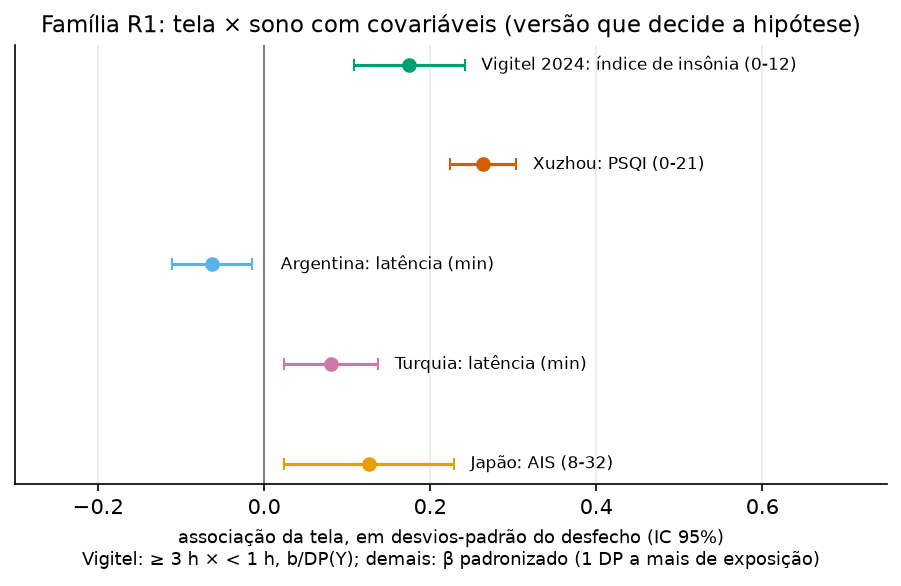

In [8]:
display(Image(filename=str(F / "efeitos_padronizados.png")))

Leitura: no Vigitel, tela digital ≥ 3 h/dia se associa a um índice de insônia cerca de 0,6 ponto maior (escala 0–12)
que < 1 h, com idade, sexo e escolaridade fixos. O ganho de R² do bloco de tela é pequeno (menos de 1%): a associação
existe, mas explica pouco da variação entre pessoas. Na Argentina o sinal é o contrário do esperado.

## 4. Família R2 — ANOVA de um fator e teste t (Vigitel)

- **ANOVA de um fator:** compara as médias das 3 faixas de tela. O F é idêntico ao F global da regressão de Y nas 2 dummies.
- **Teste t:** ≥ 3 h × < 1 h. Com variâncias iguais, o t é idêntico ao t da dummy numa regressão simples.

In [9]:
r2 = h[h.familia == "R2"].copy()
for c in ("p", "p_holm", "p_sem_peso"): r2[c] = r2[c].map(formata_p)
r2[["hipotese", "rotulo", "teste", "estatistica", "gl1", "gl2", "p", "p_holm", "decisao", "efeito_nome", "efeito", "p_sem_peso"]].round(4)

,hipotese,rotulo,teste,estatistica,gl1,gl2,p,p_holm,decisao,efeito_nome,efeito,p_sem_peso
5,H5.7,Vigitel 2024,ANOVA de um fator (3 faixas de tela),9.6052,2.0,27027,"< 0,001","< 0,001",rejeita H0,η² ponderado (R² da regressão nas dummies),0.0028,"< 0,001"
6,H5.9,Vigitel 2024,t de Welch: ≥ 3 h × < 1 h,4.0014,NaN,15774,"< 0,001","< 0,001",rejeita H0,d de Cohen ponderado (DP combinado dentro dos ...,0.1241,"< 0,001"


,base,checagem,valor_1,valor_2,dif_relativa
0,vigitel2024,F da ANOVA de um fator = F global da regressão...,3.490559e+01,3.490559e+01,2.524160e-14
1,vigitel2024,t com variâncias iguais = t da dummy na regres...,6.827440e+00,6.827440e+00,8.781043e-14
2,vigitel2024,t de Welch × t com variâncias iguais (diferem;...,6.894316e+00,6.827440e+00,9.795315e-03
3,vigitel2024,p de Welch: gl fracionário (script) × gl intei...,5.624059e-12,5.624062e-12,4.462321e-07
4,vigitel2024,d de Cohen da função = (ȳ₁ − ȳ₀)/s combinado c...,1.095789e-01,1.095789e-01,0.000000e+00


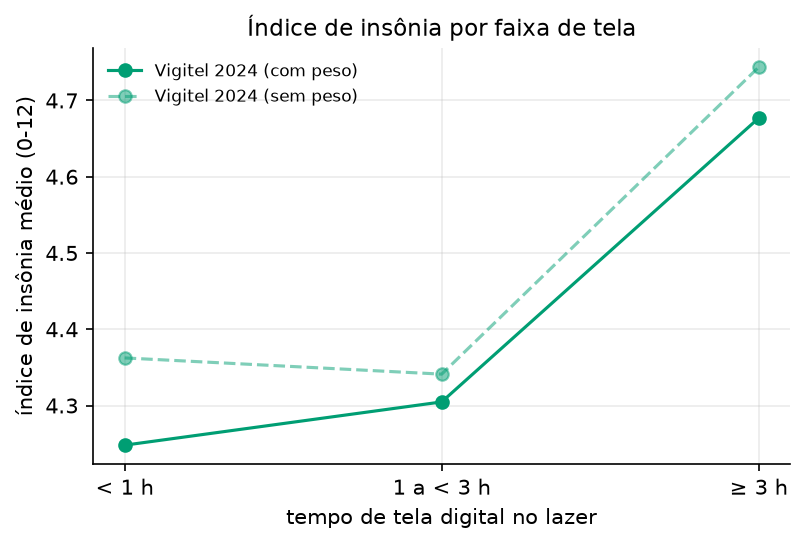

In [10]:
display(le_csv(T / "equivalencias.csv"))
display(Image(filename=str(F / "medias_por_faixa.png")))

## 5. Bruta × ajustada e sem peso × com peso

In [11]:
le_csv(T / "bruta_ajustada.csv").round(4)

,base,coeficiente,versao,b_bruta,ic_bruta,p_bruta,b_ajustada,ic_ajustada,p_ajustada,n
0,vigitel2024,tela_3h_mais,sem peso,0.3813,0.275 a 0.488,0.0000,0.5568,0.444 a 0.670,0.0000,27029
1,vigitel2024,tela_3h_mais,com peso (robusto (cada pessoa é a sua UPA)),0.4290,0.219 a 0.639,0.0001,0.5906,0.364 a 0.817,0.0000,27029
2,xuzhou,sas_sv,sem peso,0.0863,0.073 a 0.099,0.0000,0.0878,0.075 a 0.101,0.0000,2317
3,argentina,tela_presono_h,sem peso,-1.2031,-2.228 a -0.178,0.0215,-1.3225,-2.345 a -0.300,0.0113,692
4,turquia,doomscrolling,sem peso,0.1073,0.037 a 0.178,0.0028,0.1013,0.030 a 0.172,0.0051,1216
5,japao,celular_presono_h,sem peso,0.8284,0.155 a 1.502,0.0160,0.8472,0.159 a 1.535,0.0160,381


## 6. Pressupostos

Resíduo × ajustado (linearidade e variância constante), QQ-plot (normalidade), Breusch-Pagan (heterocedasticidade),
VIF (multicolinearidade) e distância de Cook (observações influentes). Com n grande, o Jarque-Bera rejeita normalidade
por desvios pequenos; o gráfico importa mais.

,base,n,breusch_pagan_lm,breusch_pagan_p,jarque_bera,jarque_bera_p,assimetria_residuos,vif_tela,vif_maximo,regressor_vif_maximo,influentes_cook_4n,pct_influentes
0,vigitel2024,27029,724.4064,0.0000,1426.1418,0.0,0.5144,1.5707,1.9814,esc_superior,1183,4.3768
1,xuzhou,2317,46.7712,0.0000,270.8374,0.0,0.6147,1.0246,1.0879,serie_2,115,4.9633
2,argentina,692,7.9303,0.1601,8445.8060,0.0,3.3423,1.0054,1.0335,esc_pais_2,28,4.0462
3,turquia,1216,5.4861,0.0644,3318.4960,0.0,2.1873,1.0178,1.0178,idade,59,4.8520
4,japao,381,3.9344,0.2686,35.2110,0.0,0.7213,1.0399,1.1209,sexo_cod2,20,5.2493


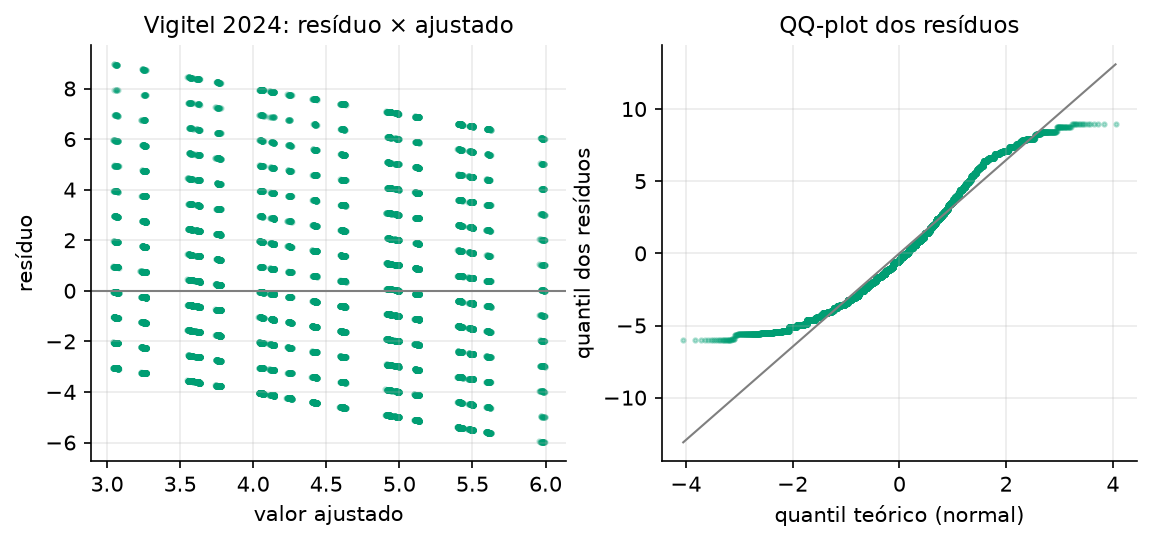

In [12]:
display(le_csv(T / "diagnostico.csv").round(4))
display(Image(filename=str(F / "diagnostico_vigitel2024.png")))

In [13]:
s = le_csv(T / "sensibilidade.csv"); s["p"] = s.p.map(formata_p)
s[["hipotese", "analise", "b", "p", "muda_em_relacao_ao_principal", "exploratoria"]].round(4)

,hipotese,analise,b,p,muda_em_relacao_ao_principal,exploratoria
0,H5.1,EP robusto HC3 (sem peso),0.5568,"< 0,001",False,False
1,H5.1,sem observações influentes (Cook > 4/n),0.5296,"< 0,001",False,False
2,H5.1,sem peso (o que o Excel calcula),0.5568,"< 0,001",False,False
3,H5.1,desfecho secundário: sono_horas (com peso),0.0947,"0,087",True,True
4,H5.3,EP robusto HC3 (sem peso),0.0878,"< 0,001",False,False
5,H5.3,sem observações influentes (Cook > 4/n),0.1029,"< 0,001",False,False
6,H5.4,EP robusto HC3 (sem peso),-1.3225,"0,001",False,False
7,H5.4,sem observações influentes (Cook > 4/n),-0.9858,"0,002",False,False
8,H5.4,log(1 + latência),-0.0622,"0,002",False,False
9,H5.4,série escolar no lugar da idade (mais casos co...,-0.7423,"0,093",True,False


## 7. Decisão

A tabela final, com p ajustado por Holm dentro de cada família, está em `resultados/005/tabelas/hipoteses.csv`, e a
leitura de cada hipótese em `resultados/005/RESUMO.md`. Lembrete: os dados são transversais, então os resultados
descrevem associação, não efeito do uso de tela.

In [14]:
display(Markdown((caminhos.RESULTADOS / "005" / "RESUMO.md").read_text(encoding="utf-8").split("## Família R2")[0].split("## Família R1")[1]))

 — coeficiente da tela na regressão múltipla

| H | Base | Y | Tela (coeficiente testado) | b (IC 95%) | t | gl | p | p Holm | Decisão | ΔR² do bloco de tela | Versão que decide |
|---|---|---|---|---|---|---|---|---|---|---|---|
| H5.1 | Vigitel 2024 | índice de insônia (0-12) | tela_3h_mais | 0,591 (0,364 a 0,817) | 5,11 | 27028 | < 0,001 | < 0,001 | rejeita H0 | 0,0038 (f² 0,0039) | com peso (robusto (cada pessoa é a sua UPA)) |
| H5.3 | Xuzhou | PSQI (0-21) | sas_sv | 0,088 (0,075 a 0,101) | 13,07 | 2308 | < 0,001 | < 0,001 | rejeita H0 | 0,0680 (f² 0,0740) | sem peso (não há desenho complexo) |
| H5.4 | Argentina | latência (min) | tela_presono_h | -1,323 (-2,345 a -0,300) | -2,54 | 686 | 0,011 | 0,023 | rejeita H0 | 0,0092 (f² 0,0094) | sem peso (não há desenho complexo) |
| H5.5 | Turquia | latência (min) | doomscrolling | 0,101 (0,030 a 0,172) | 2,81 | 1213 | 0,005 | 0,015 | rejeita H0 | 0,0064 (f² 0,0065) | sem peso (não há desenho complexo) |
| H5.6 | Japão | AIS (8-32) | celular_presono_h | 0,847 (0,159 a 1,535) | 2,42 | 377 | 0,016 | 0,023 | rejeita H0 | 0,0153 (f² 0,0155) | sem peso (não há desenho complexo) |

Leitura (um coeficiente por base, unidades do desfecho, demais variáveis fixas):

- **Vigitel (H5.1):** quem usa tela digital ≥ 3 h/dia tem índice de insônia 0,59 ponto maior (IC 0,36 a 0,82) que quem usa < 1 h, com idade, sexo e escolaridade fixos. O bloco de tela acrescenta 0,38% de R² (ponderado).
- **Xuzhou (H5.3):** cada ponto a mais no SAS-SV se associa a 0,088 ponto a mais no PSQI (IC 0,075 a 0,101); 10 pontos de SAS-SV ≈ 0,88 ponto de PSQI. Maior tamanho de efeito da família (ΔR² = 0,068).
- **Argentina (H5.4):** cada hora de tela antes de dormir se associa a -1,32 min de latência (IC -2,34 a -0,30). **O sinal é o contrário do esperado** (menos latência com mais tela). Com a série escolar no lugar da idade (mais casos completos), o p fica acima de 0,05 (ver sensibilidade).
- **Turquia (H5.5):** cada ponto de doomscrolling se associa a 0,101 min de latência (IC 0,030 a 0,172); 10 pontos ≈ 1,01 min. Rótulo da escala confirmado por evidência indireta, sem codebook (T080).
- **Japão (H5.6):** cada hora de celular nas 3 h antes de dormir se associa a 0,85 ponto a mais na AIS (IC 0,16 a 1,54).

**Testes do modelo, fora das famílias** (o que o SUMMARY OUTPUT mostra; sem peso, como no Excel):

| Base | n | R² | R² ajustado | F global (gl) | p do F global | F parcial da tela (gl) | p | ΔR² |
|---|---|---|---|---|---|---|---|---|
| Vigitel 2024 | 27029 | 0,0545 | 0,0542 | 259,36 (6; 27022) | < 0,001 | 48,54 (2; 27022) | < 0,001 | 0,0034 |
| Xuzhou | 2317 | 0,0803 | 0,0771 | 25,17 (8; 2308) | < 0,001 | 170,71 (1; 2308) | < 0,001 | 0,0680 |
| Argentina | 692 | 0,0242 | 0,0170 | 3,40 (5; 686) | 0,005 | 6,45 (1; 686) | 0,011 | 0,0092 |
| Turquia | 1216 | 0,0086 | 0,0070 | 5,26 (2; 1213) | 0,005 | 7,87 (1; 1213) | 0,005 | 0,0064 |
| Japão | 381 | 0,0158 | 0,0080 | 2,02 (3; 377) | 0,111 | 5,86 (1; 377) | 0,016 | 0,0153 |

No Japão o F global não é significativo (p = 0,111), mas o coeficiente da tela é: idade (p = 0,774) e sexo (p = 0,659) diluem o F, que testa os três coeficientes juntos. O F global não substitui o teste da hipótese.

